<div style="background:#020B21;padding:24px 26px;border-radius:8px;">
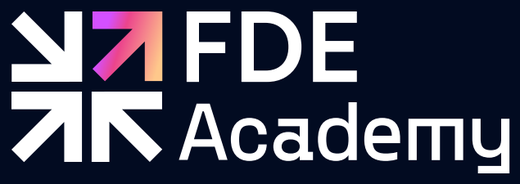<br><br>
<span style="color:#FFCA8B;font-size:13px;letter-spacing:1.5px;">TECH · LANGGRAPH-1</span><br>
<span style="color:#FFFFFF;font-size:28px;font-weight:700;">Client Zero: Hopscotch Return Watch</span><br>
<span style="color:#EC458D;font-size:14px;">State · Nodes · Edges · compile · invoke · an LLM inside a node</span>
</div>
**Format:** follow along, then change the numbers

## Where this fits in the Client Zero story

Hopscotch is an online kidswear marketplace and our running client for Phase 1. Before a Diwali sale, vendor **V5** shipped products with Chinese size tags. Onboarding checks were skipped, the sizes went live unchecked, returns spiked, and the rule-based returns chatbot refunded almost every one.

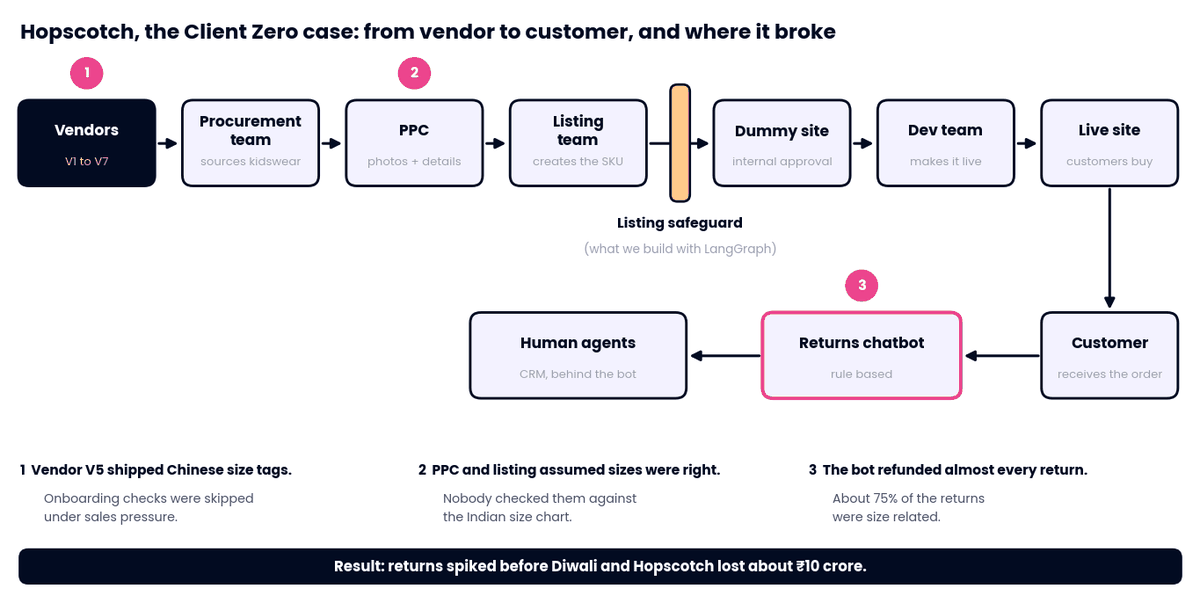

In 2019 the operations dashboard flagged the return spike. It could not say why. Today you build the first piece of a system that can: a **graph** that watches return rates and raises an alert level.

*Vendor names, the V5 incident and the loss figure come from the Client Zero session. Every other number, rule and name in this notebook is an illustrative scenario written for training, not Hopscotch data.*

## What you build today

| Part | Hopscotch task | LangGraph concept |
|---|---|---|
| 1 | Return rate for one vendor | State, one node, edges, `compile`, `invoke` |
| 2 | Alert level from the return rate | Two nodes in a sequence, passing state along |
| 3 | Ask an LLM about a vendor | An LLM call inside a node, and where its knowledge stops |

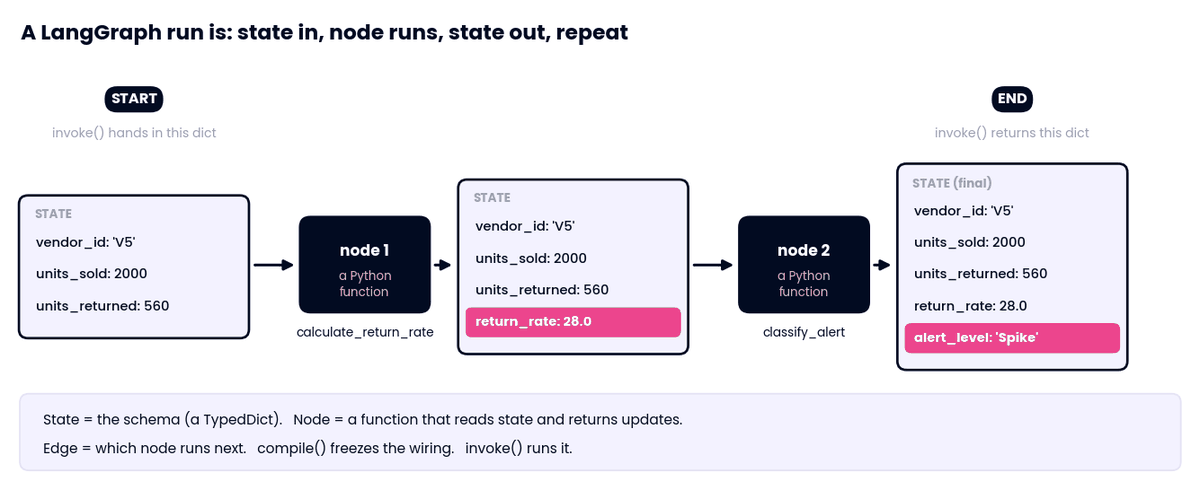

In [5]:
%pip install -q langgraph

Note: you may need to restart the kernel to use updated packages.


In [1]:
# Define the schema of the state
from typing import TypedDict

class ReturnState(TypedDict):
    vendor_id: str
    units_sold: int
    units_returned: int
    return_rate: float

In [3]:
# Define the python function to calculate return rate
# This will become a node at the end

def calculate_return_rate(state: ReturnState) -> ReturnState:
    sold = state['units_sold']
    returned = state['units_returned']
    rate = round(returned/sold * 100,2)
    state['return_rate'] = rate
    return state

In [4]:
# Define nodes and edges as the components of the graph
from langgraph.graph import StateGraph, START, END

graph = StateGraph(ReturnState)

graph.add_node("calculate_return_rate", calculate_return_rate) # Node added, alias, python function

graph.add_edge(START, 'calculate_return_rate')
graph.add_edge('calculate_return_rate', END)

workflow = graph.compile()

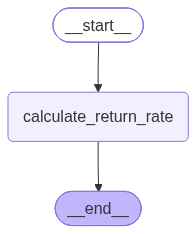

In [5]:
from IPython.display import Image, display
display(Image(workflow.get_graph().draw_mermaid_png()))

In [6]:
initial_state = {"vendor_id": "V2", "units_sold": 2000, "units_returned": 130}
final_state = workflow.invoke(initial_state)
final_state

{'vendor_id': 'V2',
 'units_sold': 2000,
 'units_returned': 130,
 'return_rate': 6.5}

In [7]:
v5_state = {"vendor_id": "V5", "units_sold": 2000, "units_returned": 560}
final_state = workflow.invoke(v5_state)
final_state

{'vendor_id': 'V5',
 'units_sold': 2000,
 'units_returned': 560,
 'return_rate': 28.0}

In [ ]:
# I want to another node, which will generate alert on specific return rate
# If return_rate< 8 = normal
# If return_rate < 15 = watch
# else = spike